# Task 4 — Trend Analysis by Release Year

Analyze release-year patterns and identify peaks and changes in the supplied Netflix catalogue.

**Project:** Auspify Technologies — Data Analysis Using Python Internship  
**Dataset:** Netflix catalogue CSV supplied for this internship  
**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn

### Import Libraries

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

### Load The Cleaned dataset

In [2]:
df = pd.read_csv("netflix_cleaned.csv")
print("Loaded cleaned dataset:", df.shape)
display(df.head())

Loaded cleaned dataset: (8790, 10)


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,2021-09-25,2020,PG-13,90 min,Documentaries
1,s3,Tv Show,Ganglands,Julien Leclercq,France,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,Tv Show,Midnight Mass,Mike Flanagan,United States,2021-09-24,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,2021-09-22,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,2021-09-24,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


## 2. Prepare release-year values
Convert release year to numeric and exclude rows where it is unavailable.

In [3]:
year_df = df.copy()
year_df["release_year"] = pd.to_numeric(year_df["release_year"], errors="coerce")
year_df = year_df.dropna(subset=["release_year"])
year_df["release_year"] = year_df["release_year"].astype(int)
print("Release year range:", year_df["release_year"].min(), "to", year_df["release_year"].max())

Release year range: 1925 to 2021


## 3. Count titles by release year

In [4]:
yearly_counts = (
    year_df.groupby("release_year")["show_id"]
    .nunique().sort_index()
)
display(yearly_counts.to_frame("title_count").tail(20))
yearly_counts.to_csv("task4_yearly_counts.csv", header=["title_count"])

,title_count
release_year,
2002,51
2003,59
2004,64
2005,80
2006,96
2007,88
2008,135
2009,152
2010,192


## 4. Full release-year trend

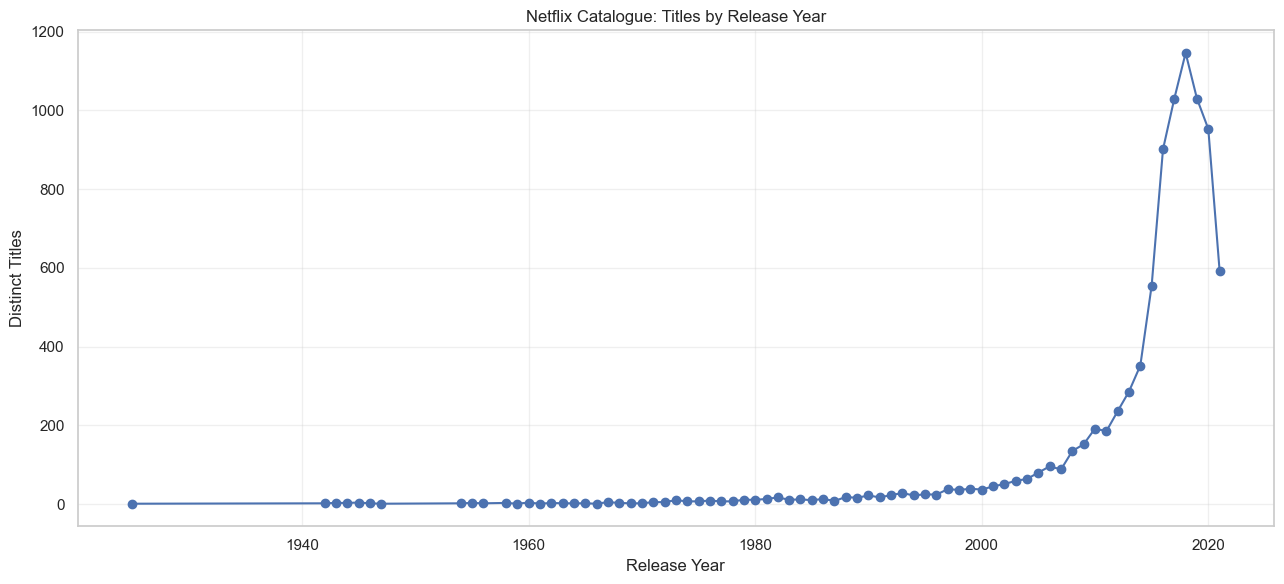

In [5]:
fig, ax = plt.subplots(figsize=(13, 6))
ax.plot(yearly_counts.index, yearly_counts.values, marker="o", linewidth=1.5)
ax.set(title="Netflix Catalogue: Titles by Release Year",
       xlabel="Release Year", ylabel="Distinct Titles")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("task4_release_year_trend.png", dpi=300, bbox_inches="tight")
plt.show()

## 5. Focus on 2000–2021

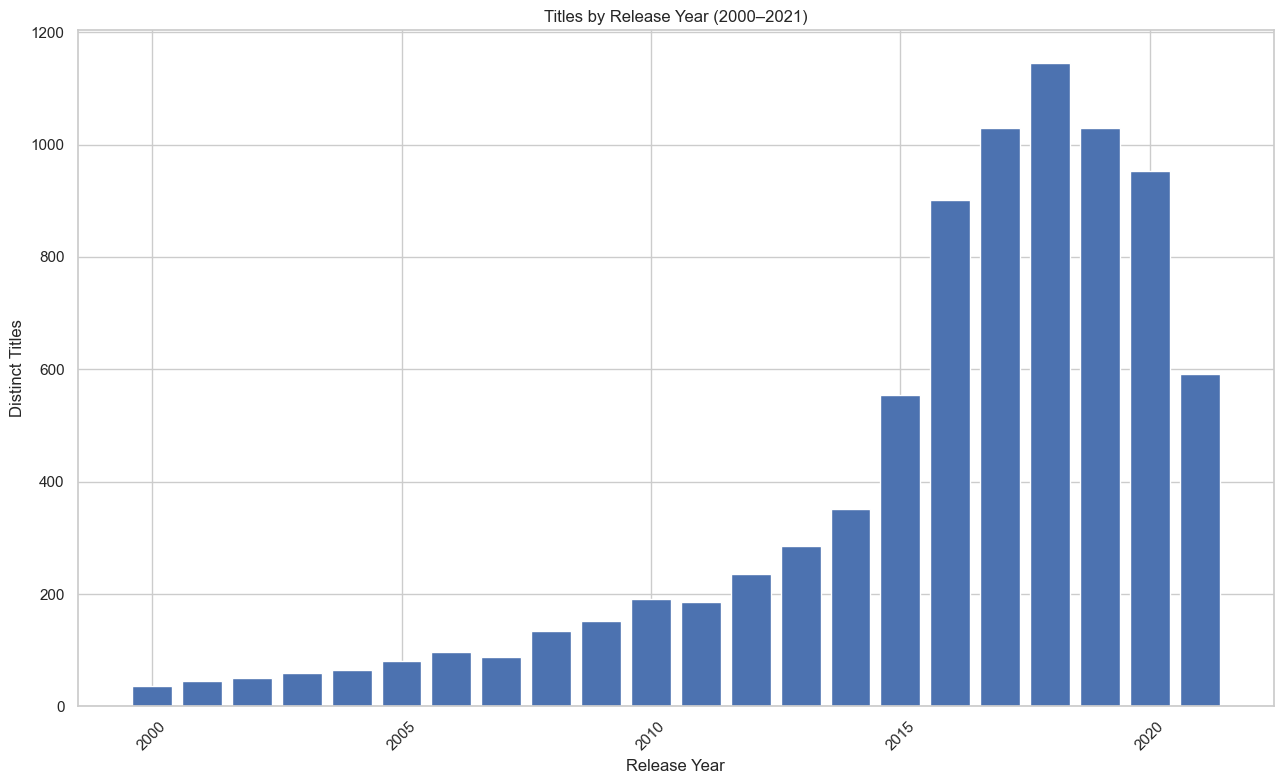

In [6]:
recent_years = yearly_counts.loc[2000:2021]
fig, ax = plt.subplots(figsize=(13, 8))
ax.bar(recent_years.index, recent_years.values)
ax.set(title="Titles by Release Year (2000–2021)",
       xlabel="Release Year", ylabel="Distinct Titles")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("task4_recent_release_years.png", dpi=300, bbox_inches="tight")
plt.show()

## 6. Highest-count years and year-over-year changes

In [7]:
top_years = yearly_counts.sort_values(ascending=False).head(10)
display(top_years.to_frame("title_count"))

yearly_changes = pd.DataFrame({
    "title_count": yearly_counts,
    "change_from_previous_year": yearly_counts.diff()
})
display(yearly_changes.tail(20))
yearly_changes.to_csv("task4_yearly_changes.csv")

,title_count
release_year,
2018,1146
2017,1030
2019,1030
2020,953
2016,901
2021,592
2015,555
2014,352
2013,286


,title_count,change_from_previous_year
release_year,,
2002,51,6.0
2003,59,8.0
2004,64,5.0
2005,80,16.0
2006,96,16.0
2007,88,-8.0
2008,135,47.0
2009,152,17.0
2010,192,40.0


## 7. Interpretation
Identify the highest-count years and describe increases or decreases. Important: this chart describes the original release years of titles in the supplied catalogue, not the number of titles Netflix produced each year. The latest years may be incomplete.